In [20]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("../data/processed")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Muat ulang jika variabel belum ada di sesi ini
full = pd.read_csv(DATA_DIR / "tomat_harian_bersih.csv", index_col=0, parse_dates=True).asfreq("D")
y = full["harga_bersih"].rename("y")
diimputasi = full["diimputasi"].astype(bool)

print(f"Jumlah observasi: {len(y):,} | {y.index.min().date()} s.d. {y.index.max().date()}")
print(y.describe().round(0).to_string())

Jumlah observasi: 1,339 | 2023-01-01 s.d. 2026-08-31
count     1339.0
mean     11960.0
std       4173.0
min       5000.0
25%       8857.0
50%      11571.0
75%      13429.0
max      29143.0


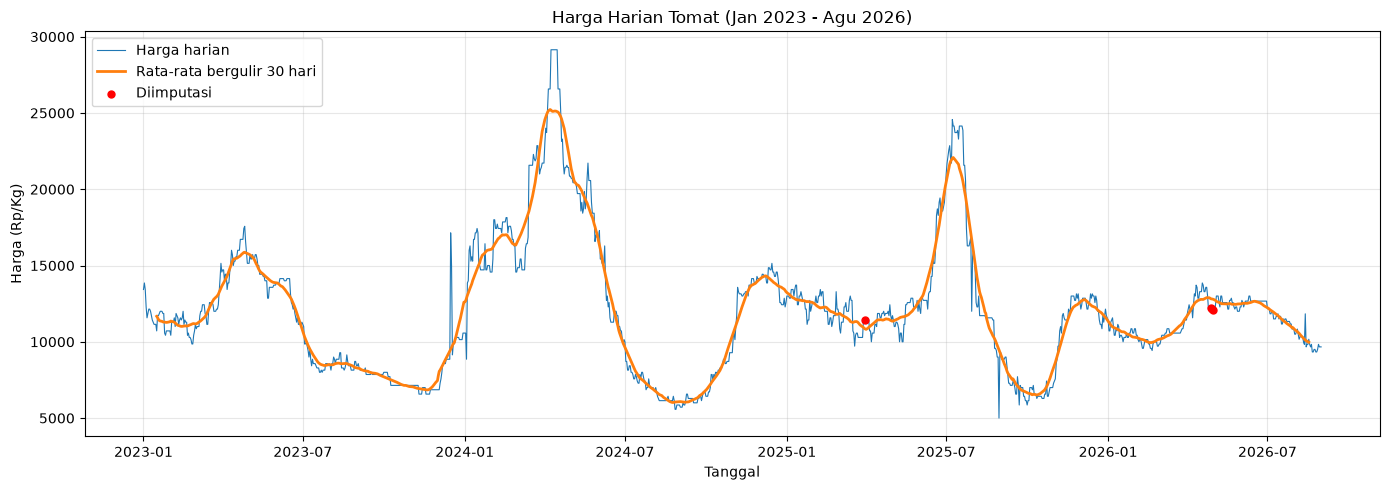

In [21]:
# Plot time series harga harian tomat
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(y.index, y.values, lw=0.8, color="tab:blue", label="Harga harian")
ax.plot(y.rolling(30, center=True).mean(), lw=2, color="tab:orange", label="Rata-rata bergulir 30 hari")

# Tandai hari hasil imputasi
ax.scatter(y.index[diimputasi], y[diimputasi], color="red", s=25, zorder=3, label="Diimputasi")

ax.set_title("Harga Harian Tomat (Jan 2023 - Agu 2026)")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Harga (Rp/Kg)")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig(FIG_DIR / "tomat_deret_waktu_keseluruhan.png", dpi=150)
plt.show()

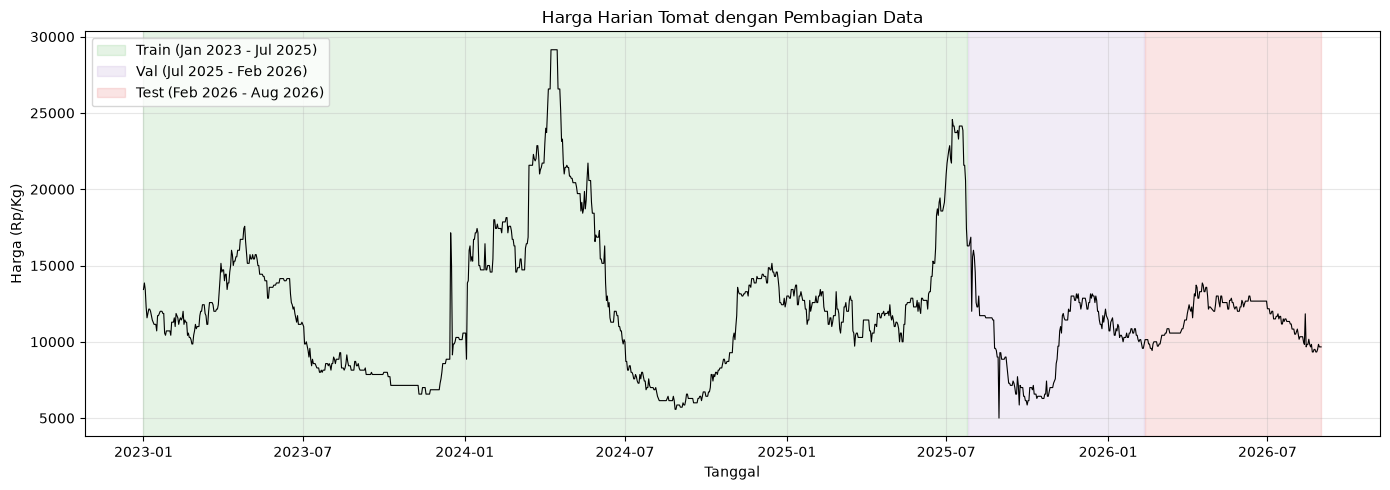

In [22]:
n = len(y)
i_train, i_val = int(n * 0.70), int(n * 0.85)
batas = {
    "Train": (y.index[0], y.index[i_train - 1], "tab:green"),
    "Val":   (y.index[i_train], y.index[i_val - 1], "tab:purple"),
    "Test":  (y.index[i_val], y.index[-1], "tab:red"),
}

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y.index, y.values, lw=0.8, color="black")

for nama, (awal, akhir, warna) in batas.items():
    ax.axvspan(awal, akhir, color=warna, alpha=0.12, label=f"{nama} ({awal:%b %Y} - {akhir:%b %Y})")

ax.set_title("Harga Harian Tomat dengan Pembagian Data")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Harga (Rp/Kg)")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig(FIG_DIR / "tomat_deret_dengan_split.png", dpi=150)
plt.show()

In [23]:
import warnings
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)

train = pd.read_csv(
    "../data/processed/tomat_train.csv",
    index_col=0,
    parse_dates=True
)["y"].asfreq("D")

print(
    f"Train: {train.index[0].date()} s.d. "
    f"{train.index[-1].date()} ({len(train)} hari)\n"
)


def uji_stasioner(x, regresi="c"):
    """regresi: 'c' = konstanta, 'ct' = konstanta + tren"""

    adf_stat, adf_p, adf_lag, _, adf_crit, _ = adfuller(
        x, regression=regresi, autolag="AIC"
    )

    kpss_stat, kpss_p, _, kpss_crit = kpss(
        x, regression=regresi, nlags="auto"
    )

    # Kesimpulan berdasarkan ADF
    simpulan = "STASIONER" if adf_p < 0.05 else "TIDAK STASIONER"

    return {
        "spec": regresi,
        "ADF_stat": round(adf_stat, 3),
        "ADF_p": round(adf_p, 4),
        "ADF_lag": adf_lag,
        "ADF_crit_5%": round(adf_crit["5%"], 3),
        "KPSS_stat": round(kpss_stat, 3),
        "KPSS_p": round(kpss_p, 4),
        "KPSS_crit_5%": round(kpss_crit["5%"], 3),
        "kesimpulan": simpulan
    }


hasil = pd.DataFrame([
    uji_stasioner(train, "c"),
    uji_stasioner(train, "ct")
])

print(hasil.to_string(index=False))

Train: 2023-01-01 s.d. 2025-07-25 (937 hari)

spec  ADF_stat  ADF_p  ADF_lag  ADF_crit_5%  KPSS_stat  KPSS_p  KPSS_crit_5%      kesimpulan
   c    -2.078 0.2535        4       -2.865      0.248  0.1000         0.463 TIDAK STASIONER
  ct    -2.123 0.5334        4       -3.415      0.182  0.0227         0.146 TIDAK STASIONER


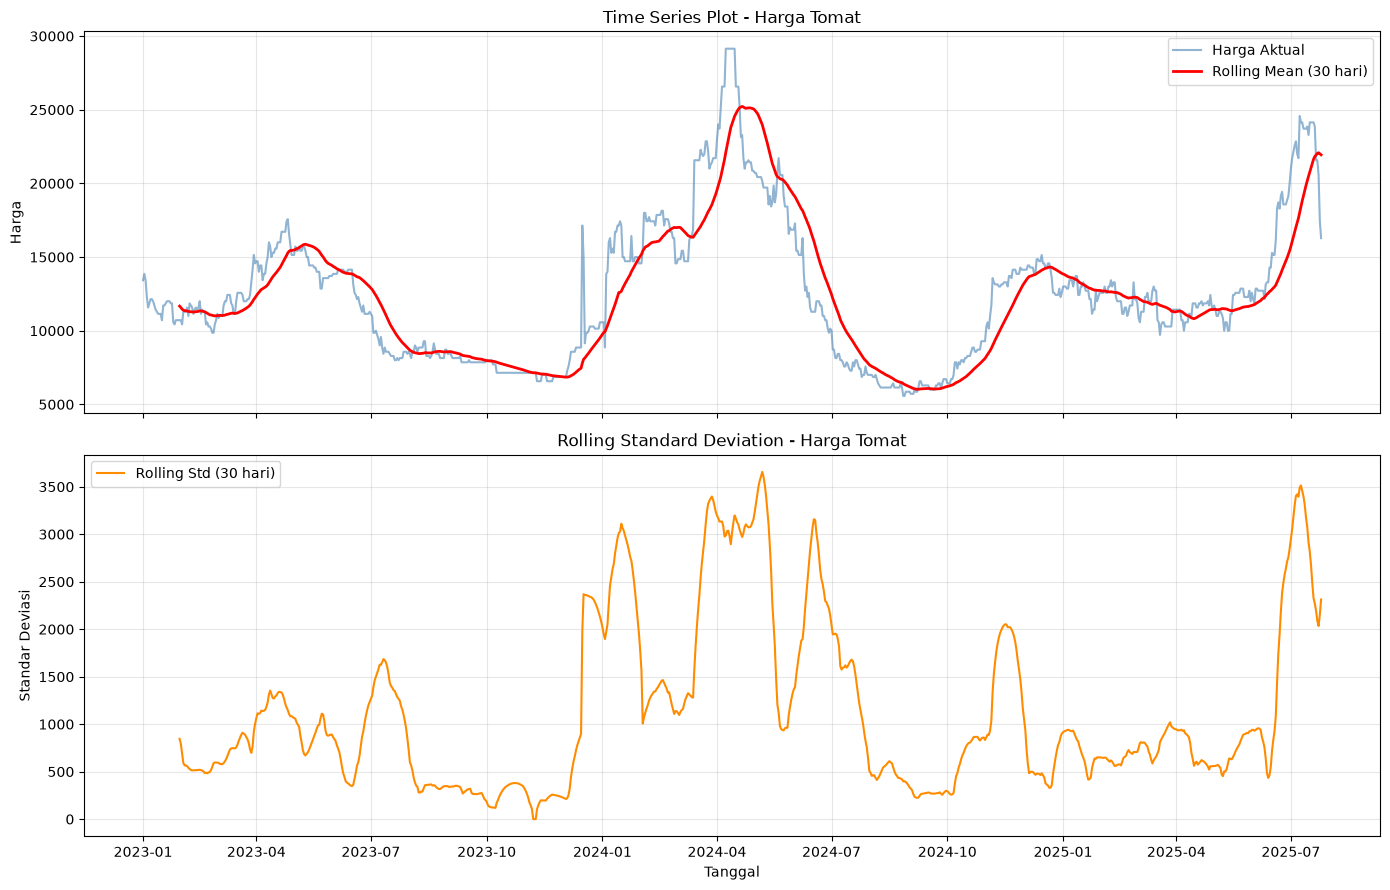

In [19]:
import matplotlib.pyplot as plt

window = 30

# Menghitung rolling statistics
rolling_mean = train.rolling(window=window).mean()
rolling_std = train.rolling(window=window).std()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Plot harga dan rolling mean
axes[0].plot(
    train.index, train,
    label="Harga Aktual",
    color="steelblue",
    alpha=0.6
)

axes[0].plot(
    rolling_mean.index, rolling_mean,
    label=f"Rolling Mean ({window} hari)",
    color="red",
    linewidth=2
)

axes[0].set_title("Time Series Plot - Harga Tomat")
axes[0].set_ylabel("Harga")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot rolling standard deviation
axes[1].plot(
    rolling_std.index, rolling_std,
    label=f"Rolling Std ({window} hari)",
    color="darkorange",
    linewidth=1.5
)

axes[1].set_title("Rolling Standard Deviation - Harga Tomat")
axes[1].set_ylabel("Standar Deviasi")
axes[1].set_xlabel("Tanggal")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Rolling Mean: berubah cukup signifikan sepanjang periode pengamatan. Terlihat kenaikan harga pada awal 2024, penurunan pada pertengahan 2024, dan kenaikan kembali pada pertengahan 2025.
- Rolling Std: mengalami fluktuasi yang cukup besar. Artinya, varians harga belum terlihat stabil sepanjang waktu.

perlu dilakukan differencing